In [3]:
import json
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from optbinning import BinningProcess

In [4]:
df = pd.read_csv('data/dataset_msp_credit.csv', encoding='utf-8-sig')
dct = pd.read_csv('data/dataset_dictionary.csv', encoding='utf-8-sig')
df = df[df.in_model_sample == 1]
train, test = df[df.split == 'train'], df[df.split == 'test']

In [5]:
FEATURES = dct.loc[dct.role.isin(['признак модели', 'пустышка']), 
                   'column'].tolist()
DUMMIES = dct.loc[dct.role == 'пустышка', 'column'].tolist()
CATEGORICAL = dct.loc[dct.column.isin(FEATURES) & 
                      (dct.dtype == 'str'), 'column'].tolist()

In [6]:
# корзины, WoE и IV по каждому признаку; отбор IV ≥ 0,02
BFP = {f: {'monotonic_trend': 'auto_asc_desc'} for f in FEATURES if f not in CATEGORICAL}
BFP['current_overdue_days'] = {'user_splits': [0.5, 29.5], 'min_bin_size': 0.005}
BFP['overdue_30plus_flag_24m'] = {'user_splits': [0.5], 'min_bin_size': 0.005}

bp = BinningProcess(
    variable_names=FEATURES,
    categorical_variables=CATEGORICAL,
    max_n_bins=6, min_bin_size=0.025,          
    selection_criteria={'iv': {'min': 0.02}},
    binning_fit_params=BFP,
)

bp.fit(train[FEATURES], train.default_12m)
summary = bp.summary().sort_values('iv', ascending=False).reset_index(drop=True)
summary[['name', 'dtype', 'n_bins', 'iv', 'gini', 'quality_score', 'selected']]

,name,dtype,n_bins,iv,gini,quality_score,selected
0,zero_balance_days_90d,numerical,6,0.504945,0.382188,0.866201,True
1,dscr_new,numerical,6,0.453564,0.364222,0.9182,True
2,avg_monthly_net_cashflow_6m,numerical,6,0.416626,0.349983,0.946589,True
3,months_since_last_overdue,numerical,3,0.408612,0.291589,0.509439,True
4,overdue_events_24m,numerical,2,0.386797,0.281163,0.63964,True
5,ebit_margin,numerical,6,0.318211,0.264579,0.268734,True
6,tax_paid_on_time_share,numerical,6,0.270775,0.282409,0.810844,True
7,inflow_cv_rel_6m,numerical,6,0.260367,0.265218,0.78909,True
8,revenue_growth_yoy,numerical,6,0.235677,0.263961,0.752098,True
9,top1_counterparty_share,numerical,6,0.231813,0.261511,0.702471,True


In [7]:
# пустышки должны отсеяться (IV < 0,02)
summary[summary.name.isin(DUMMIES)][['name', 'iv', 'selected']]

,name,iv,selected
43,region_code,0.00692,False
44,dummy_num_1,0.004768,False
45,dummy_cat,0.004125,False
46,dummy_num_2,0.004099,False


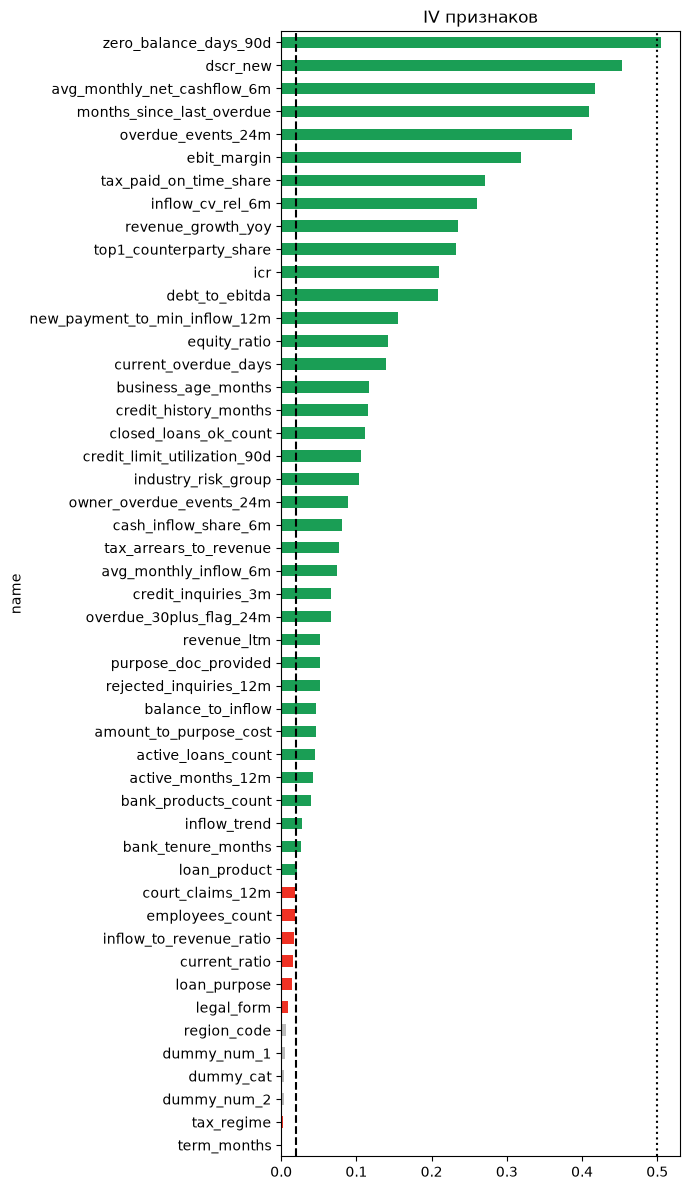

In [8]:
# IV признаков: серые — пустышки, зелёные — отобраны, красные — отсеяны
ax = summary.set_index('name').iv.sort_values().plot.barh(figsize=(7, 12), color=[
    '#bbb' if n in DUMMIES else ('#1a9e55' if s else '#ef3124')
    for n, s in summary.set_index('name').sort_values('iv')[['selected']].itertuples()])
ax.axvline(0.02, ls='--', c='k')
ax.axvline(0.5, ls=':', c='k')
ax.set_title('IV признаков')
plt.tight_layout()

In [9]:
# IV > 0,5 — проверить на утечку цели
for name in summary.loc[summary.iv > 0.5, 'name']:
    print(name)

zero_balance_days_90d


In [10]:
# пример таблицы корзин одного признака
ob = bp.get_binned_variable('months_since_last_overdue')
ob.binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 6.50)",1550,0.100123,1166,384,0.247742,-1.203172,0.232090,0.027379
1,"[6.50, 24.50)",1546,0.099864,1295,251,0.162354,-0.673051,0.059406,0.007289
2,"[24.50, inf)",12385,0.800013,11627,758,0.061203,0.416538,0.117115,0.014534
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,15481,1.000000,14088,1393,0.089981,,0.408612,0.049202


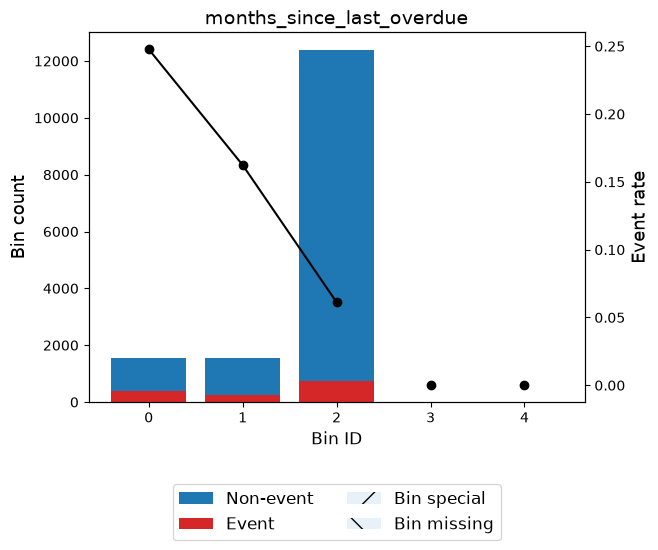

In [11]:
# доля дефолтов по корзинам
ob.binning_table.plot(metric='event_rate')

In [12]:
# убираем дубли: из пары с корреляцией WoE > 0,7 остаётся признак с большим IV
selected = summary.loc[summary.selected, 'name'].tolist()
W = bp.transform(train[FEATURES], metric='woe')[selected]
final, dropped = [], []
for f in selected:                                  # от сильного к слабому
    partner = next((g for g in final if abs(np.corrcoef(W[f], W[g])[0, 1]) > 0.7), None)
    (dropped.append((f, partner, round(abs(np.corrcoef(W[f], W[partner])[0, 1]), 2))) if partner else final.append(f))
print('убраны по корреляции:', dropped)
print(f'итог: {len(final)} признаков')

убраны по корреляции: [('overdue_events_24m', 'months_since_last_overdue', np.float64(0.98)), ('debt_to_ebitda', 'icr', np.float64(0.89)), ('revenue_ltm', 'avg_monthly_inflow_6m', np.float64(0.84))]
итог: 34 признаков


In [13]:
# сохраняем отобранные признаки и таблицу IV
json.dump({'features': final, 'categorical': [c for c in final if c in CATEGORICAL]},
          open('model/selected_features.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
summary.to_csv('model/iv_summary.csv', index=False)
final

['zero_balance_days_90d',
 'dscr_new',
 'avg_monthly_net_cashflow_6m',
 'months_since_last_overdue',
 'ebit_margin',
 'tax_paid_on_time_share',
 'inflow_cv_rel_6m',
 'revenue_growth_yoy',
 'top1_counterparty_share',
 'icr',
 'new_payment_to_min_inflow_12m',
 'equity_ratio',
 'current_overdue_days',
 'business_age_months',
 'credit_history_months',
 'closed_loans_ok_count',
 'credit_limit_utilization_90d',
 'industry_risk_group',
 'owner_overdue_events_24m',
 'cash_inflow_share_6m',
 'tax_arrears_to_revenue',
 'avg_monthly_inflow_6m',
 'credit_inquiries_3m',
 'overdue_30plus_flag_24m',
 'purpose_doc_provided',
 'rejected_inquiries_12m',
 'balance_to_inflow',
 'amount_to_purpose_cost',
 'active_loans_count',
 'active_months_12m',
 'bank_products_count',
 'inflow_trend',
 'bank_tenure_months',
 'loan_product']